# **Projeto Final — Aprendizado de Máquina I (2026.2) · Parte II: aplicação de redes neurais**
### Grupo: *Machine Learning Name in progress*

- Tipo de problema: **Classificação**
- Conjunto de dados: [**Brain Cancer Gene Expression (CuMiDa)**](http://kaggle.com/datasets/brunogrisci/brain-cancer-gene-expression-cumida)
- Objetivo principal: **Usar redes neurais para classificar os casos com tipos de câncer cerebral**


- **Equipe responsável**
    - Mateus Bandeira
- **Revisão** 
    - Lucas Vieira
    - Mateus Almeida

## 0. Configuração e reprodutibilidade

- Semente global: `67`
- Instalação: `pip install "mlnip-lib @ git+https://github.com/Machine-Learning-Name-in-progress/ML-Library@<hash>"`

### 0.1 Imports

In [ ]:
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Biblioteca do grupo
from ml_library.metrics.classification_metrics import (
    accuracy,
    confusion_matrix,
    f1_score,
    log_loss,
    precision,
    recall,
)
from ml_library.model_selection.grid_search_cv import grid_search_cv
from ml_library.model_selection.kfold import kfold_indices
from ml_library.models.unsupervised.pca import PCA
from ml_library.preprocessing.one_hot import one_hot
from ml_library.preprocessing.standardization import standardization
from ml_library.utils._random import set_seed

from ml_library.models.neural_network import (
    ReLU,
    LeakyReLU,
    Tanh,
    MLPClassifier,
    SGD,
    Adam,
    AdamW,
    Sigmoid,
    Linear
)

### 0.2 Semente e constantes globais

In [28]:
SEED = 67
set_seed(SEED)
rng = np.random.default_rng(SEED)

KAGGLE_DATASET = "brunogrisci/brain-cancer-gene-expression-cumida"
CSV_FILENAME = "Brain_GSE50161.csv"
TARGET = "type" 

TEST_SIZE = 0.2
N_FOLDS = 5  

## 1. Problema e dados

- Pergunta: é possivel fazer uma boa classificação dos tipos de cancer cerebral usando a biblioteca?
- Métrica principal: Acurácia, seguida de F1-Score

### 1.1 Carregamento dos dados

In [29]:
import shutil

DATA_DIR = Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)
LOCAL_CSV_PATH = DATA_DIR / CSV_FILENAME

if not LOCAL_CSV_PATH.exists():
    downloaded_dir = Path(kagglehub.dataset_download(KAGGLE_DATASET))
    shutil.copy2(downloaded_dir / CSV_FILENAME, LOCAL_CSV_PATH)

df = pd.read_csv(LOCAL_CSV_PATH)
df.shape

(130, 54677)

### 1.2 Dicionário de variáveis

| Variável | Tipo | Unidade | Descrição |
|---|---|---|---|
| `samples` | identificador (`int64`) | — | ID da amostra biológica no estudo GSE50161 |
| `type` | categórica (`str`) | — | classe-alvo: `ependymoma` (46), `glioblastoma` (34), `medulloblastoma` (22), `pilocytic_astrocytoma` (15) e `normal` (13) |
| `1007_s_at` … `AFFX-*` (54.675 colunas) | numérica (`float64`) | intensidade $\log_2$ (RMA) | níveis de expressão gênica medidos por microarray Affymetrix Human Genome U133 Plus 2.0 |

## 2. Preparação dos dados (Divisão treino/teste e Pré-processamento)

Divisão estratificada e padronização calculada **só no treino** e aplicada no conjunto de validação/teste.

- Variance Thresholding
- Padronização com standardizing()
- PCA para redução de dimensões (colunas)

In [30]:
threshold = 0.5

X_test = df.groupby(TARGET, group_keys=False).sample(
    frac=TEST_SIZE, random_state=SEED
)
X_train = df.drop(X_test.index)
X_train = X_train.sample(frac=1, random_state=SEED).reset_index(drop=True)
X_test = X_test.reset_index(drop=True)

# Filtro de variancia para remover colunas com baixa variância
gene_cols = [c for c in df.columns if c not in ["samples", TARGET]]
X_tr_scaled, scale_params = standardization(X_train[gene_cols])
stds = pd.Series({col: scale_params[col]["std"] for col in gene_cols})
cutoff = stds.quantile(0.80)
selected_genes = stds[stds >= cutoff].index
print(f"Genes originais: {len(gene_cols)}")
print(f"Genes selecionados depois do filtro: {len(selected_genes)}")
X_tr_final = X_tr_scaled[selected_genes].to_numpy()
X_te_df = X_test[selected_genes].copy()
for col in selected_genes:
    m = scale_params[col]["mean"]
    s = scale_params[col]["std"]
    # Padronização:
    X_te_df[col] = (X_te_df[col] - m) / s if s > 0 else 0.0
X_te_final = X_te_df.to_numpy()
N_COMPONENTS = 50
pca_model = PCA(n_components=N_COMPONENTS, solver='svd', standardize=False)
pca_model.fit(X_tr_final)
# Matrizes finais prontas para a rede neural:
X_tr_pca = pca_model.transform(X_tr_final)
X_te_pca = pca_model.transform(X_te_final)
print(f"Shape final Treino para a Rede: {X_tr_pca.shape}")
print(f"Shape final Teste para a Rede:  {X_te_pca.shape}")

Genes originais: 54675
Genes selecionados depois do filtro: 10935
Shape final Treino para a Rede: (104, 50)
Shape final Teste para a Rede:  (26, 50)


In [31]:
# coluna y alvo para treino e teste:
y_train = one_hot(X_train[[TARGET]], columns=[TARGET], drop=True)
y_test = one_hot(X_test[[TARGET]], columns=[TARGET], drop=True)
class_cols = sorted(y_train.columns)

y_train = y_train[class_cols].to_numpy()
y_test = y_test[class_cols].to_numpy()

#indices inteiros para calcular métricas de classificação:
# acurácia, f1-score, matriz de confusão, etc.
y_train_idx = np.argmax(y_train, axis=1)
y_test_idx = np.argmax(y_test, axis=1)
labels_list = list(range(len(class_cols)))

## 3. Modelo: Rede Neural (MLP)

| Modelo | Classe/função da biblioteca | Hiperparâmetros | Por que testar |
|---|---|---|---|
| Baseline (Classe majoritária) | — | — | referência mínima de desempenho |
| Rede neural (`MLPClassifier`) | `MLPClassifier`, `Dense`, `ReLU`/`LeakyReLU`/`Tanh`/`Sigmoid`/`Linear`, `Softmax`, `CategoricalCrossEntropy`, `SGD`/`Adam`/`AdamW` | `hidden_units`, `lr`, `epochs`, `activation`, `optimizer` | aprende representações não lineares a partir dos componentes principais de expressão gênica para classificar os 5 tipos |


### 3.1 Baseline

In [32]:
# Classe mais frequente no conjunto de treino:
majority_class = int(pd.Series(y_train_idx).mode()[0])

# predição baseline no treino e teste:
y_train_baseline = np.full_like(y_train_idx, fill_value=majority_class)
y_test_baseline = np.full_like(y_test_idx, fill_value=majority_class)

print(f"Classe majoritária: {majority_class}")
print(f"Acurácia baseline no treino: {accuracy(y_train_idx.tolist(),
                                     y_train_baseline.tolist()):.4f}")
print(f"Acurácia baseline no teste: {accuracy(y_test_idx.tolist(),
                                    y_test_baseline.tolist()):.4f}")

Classe majoritária: 0
Acurácia baseline no treino: 0.3558
Acurácia baseline no teste: 0.3462


### 3.2 Arquitetura da Rede Neural:

50 entradas (após PCA) -> Hidden Layer -> 5 saídas com Softmax | uma pra cada tipo

In [33]:
set_seed(SEED)
mlp_base = MLPClassifier(
    hidden_units=32,
    lr=0.01,
    epochs=200,
    activation=ReLU,
    optimizer=Adam).fit(X_tr_pca, y_train)

y_train_pred = mlp_base.predict(X_tr_pca)

print(f'Camada oculta: {mlp_base._hidden.weights.shape}')
print(f'Camada de saída (Softmax): {mlp_base._output.weights.shape}')

print(f"Acurácia no treino: {accuracy(y_train_idx, y_train_pred):.4f}")



Camada oculta: (50, 32)
Camada de saída (Softmax): (32, 5)
Acurácia no treino: 1.0000


## 4. Validação e busca de hiperparâmetros

Usar **só o conjunto de treino**. O teste não aparece nesta seção.

In [34]:
# Grade de hiperparâmetros para encontrar o melhor modelo geral:
param_grid = {
    "hidden_units": [16, 32, 64],
    "lr": [0.001, 0.01],
    "epochs": [200],
    "activation": [ReLU, LeakyReLU, Tanh, Sigmoid, Linear],
    "optimizer": [SGD, Adam, AdamW],
}

set_seed(SEED)
search_results = grid_search_cv(
    model=MLPClassifier,
    param_grid=param_grid,
    X=X_tr_pca,
    y=y_train_idx,
    k=N_FOLDS,
    scoring=accuracy,
    greater_is_better=True,
)

# Avaliar TODAS as combinações ativação-otimizador na validação, cross val
# fixando hidden_units, lr e epochs do melhor modelo para comparação justa:
best_params = search_results["best_params"]
cv_rows = []
candidate_models = {}

for act_cls in param_grid["activation"]:
    for opt_cls in param_grid["optimizer"]:
        set_seed(SEED)
        res = grid_search_cv(
            model=MLPClassifier,
            param_grid={
                "hidden_units": [best_params["hidden_units"]],
                "lr": [best_params["lr"]],
                "epochs": [best_params["epochs"]],
                "activation": [act_cls],
                "optimizer": [opt_cls],
            },
            X=X_tr_pca,
            y=y_train_idx,
            k=N_FOLDS,
            scoring=accuracy,
            greater_is_better=True,
        )
        key = f"{act_cls.__name__} + {opt_cls.__name__}"
        candidate_models[key] = {
            "activation": act_cls.__name__,
            "optimizer": opt_cls.__name__,
            "cv_score": res["best_score"],
            "estimator": res["best_estimator"],
        }
        cv_rows.append(
            {
                "Modelo": key,
                "Ativação": act_cls.__name__,
                "Otimizador": opt_cls.__name__,
                "Acc Validação (5-Fold)": res["best_score"],
                "Loss Final (Treino)": res["best_estimator"].loss_history[-1],
            }
        )

cv_df = (
    pd.DataFrame(cv_rows)
    .sort_values(by="Acc Validação (5-Fold)", ascending=False)
    .reset_index(drop=True)
)
display(cv_df.round(4))


,Modelo,Ativação,Otimizador,Acc Validação (5-Fold),Loss Final (Treino)
0,Sigmoid + Adam,Sigmoid,Adam,0.9429,0.0086
1,Sigmoid + AdamW,Sigmoid,AdamW,0.9429,0.0090
2,Tanh + AdamW,Tanh,AdamW,0.9238,0.0037
3,Tanh + Adam,Tanh,Adam,0.9238,0.0036
4,ReLU + AdamW,ReLU,AdamW,0.8762,0.0000
5,LeakyReLU + AdamW,LeakyReLU,AdamW,0.8762,0.0000
6,LeakyReLU + Adam,LeakyReLU,Adam,0.8762,0.0000
7,ReLU + Adam,ReLU,Adam,0.8667,0.0000
8,Linear + AdamW,Linear,AdamW,0.8562,0.0000
9,Linear + Adam,Linear,Adam,0.8562,0.0000


## 5. Avaliação final no conjunto de teste

Treino final com os melhores hiperparâmetros, métricas no conjunto de teste e gráficos (curva de loss / matriz de confusão).

In [ ]:
best_params = search_results["best_params"]
print("Melhores hiperparâmetros encontrados:")
for param, value in best_params.items():
    print(f"{param}: {value}")

best_val_accuracy = search_results["best_score"]
print(f"\nMelhor acurácia de validação cruzada, 5-fold: \
       {best_val_accuracy:.4f}")

best_mlp = search_results["best_estimator"]
print(f"Resumo do melhor modelo encontrado: {best_mlp}")

y_test_pred = best_mlp.predict(X_te_pca)
y_test_proba = best_mlp.predict_proba(X_te_pca)

# Métricas da ml_library no teste, pro best model
acc_test = accuracy(y_test_idx, y_test_pred)
prec_test = precision(y_test_idx, y_test_pred, labels_list)
rec_test = recall(y_test_idx, y_test_pred, labels_list)
f1_test = f1_score(y_test_idx, y_test_pred, labels_list)
ll_test = log_loss(y_test_idx, y_test_proba, labels_list)
cm = confusion_matrix(y_test_idx, y_test_pred, labels_list)

acc_base = accuracy(y_test_idx, y_test_baseline)
print(f"\nAcurácia no Teste:  {acc_test:.4f}  (Baseline: {acc_base:.4f})")
print(f"F1-Score (Macro):   {np.mean(f1_test):.4f}")
print(f"Precisão (Macro):   {np.mean(prec_test):.4f}")
print(f"Recall (Macro):     {np.mean(rec_test):.4f}")
print(f"Log-Loss no Teste:  {ll_test:.4f}")

# comparação de todos os modelos possíveis
test_rows = []
for key, info in candidate_models.items():
    est = info["estimator"]
    y_tr_p = est.predict(X_tr_pca)
    y_te_p = est.predict(X_te_pca)
    y_te_prob = est.predict_proba(X_te_pca)

    test_rows.append(
        {
            "Modelo": key,
            "Ativação": info["activation"],
            "Otimizador": info["optimizer"],
            "Acc Treino": accuracy(y_train_idx, y_tr_p),
            "Acc Validação (CV)": info["cv_score"],
            "Acc Teste": accuracy(y_test_idx, y_te_p),
            "F1 (Macro)": np.mean(f1_score(y_test_idx, y_te_p, labels_list)),
            "Precisão (Macro)": np.mean(
                precision(y_test_idx, y_te_p, labels_list)
            ),
            "Recall (Macro)": np.mean(recall(y_test_idx, y_te_p, labels_list)),
            "Log-Loss (Teste)": log_loss(y_test_idx, y_te_prob, labels_list),
        }
    )

print("\nComparação geral dos modelos avaliados no Teste:")
comparison_df = (
    pd.DataFrame(test_rows)
    .sort_values(by=["Acc Teste", "F1 (Macro)"], ascending=False)
    .reset_index(drop=True)
)
display(comparison_df.round(4))

Melhores hiperparâmetros encontrados:
hidden_units: 32
lr: 0.01
epochs: 200
activation: <class 'ml_library.models.neural_network.activations.Sigmoid'>
optimizer: <class 'ml_library.models.neural_network.optimizers.Adam'>

Melhor acurácia de validação cruzada, 5-fold:        0.9429
Resumo do melhor modelo encontrado: <ml_library.models.neural_network.mlp.MLPClassifier object at 0x72197eca7c20>

Acurácia no Teste:  0.8846  (Baseline: 0.3462)
F1-Score (Macro):   0.8844
Precisão (Macro):   0.9400
Recall (Macro):     0.8611
Log-Loss no Teste:  0.2769

Comparação geral dos modelos avaliados no Teste:


,Modelo,Ativação,Otimizador,Acc Treino,Acc Validação (CV),Acc Teste,F1 (Macro),Precisão (Macro),Recall (Macro),Log-Loss (Teste)
0,ReLU + Adam,ReLU,Adam,1.0000,0.8667,0.9231,0.9114,0.9636,0.8833,0.7457
1,ReLU + AdamW,ReLU,AdamW,1.0000,0.8762,0.9231,0.9114,0.9636,0.8833,0.7167
2,LeakyReLU + Adam,LeakyReLU,Adam,1.0000,0.8762,0.9231,0.9114,0.9636,0.8833,0.7278
3,LeakyReLU + AdamW,LeakyReLU,AdamW,1.0000,0.8762,0.9231,0.9114,0.9636,0.8833,0.6994
4,Linear + SGD,Linear,SGD,1.0000,0.8271,0.9231,0.8873,0.9400,0.8667,0.2966
5,Tanh + Adam,Tanh,Adam,1.0000,0.9238,0.8846,0.8921,0.8992,0.8992,0.3744
6,Tanh + AdamW,Tanh,AdamW,1.0000,0.9238,0.8846,0.8921,0.8992,0.8992,0.3723
7,Linear + Adam,Linear,Adam,1.0000,0.8562,0.8846,0.8842,0.9333,0.8611,1.1609
8,Linear + AdamW,Linear,AdamW,1.0000,0.8562,0.8846,0.8842,0.9333,0.8611,1.1185
9,Sigmoid + Adam,Sigmoid,Adam,1.0000,0.9429,0.8462,0.8406,0.8778,0.8325,0.3241


In [36]:
class_names = [c.replace(f"{TARGET}_", "").replace("_onehot", "")
                for c in class_cols]
metrics_df = pd.DataFrame(
    {"Precisão": prec_test, "Recall": rec_test, "F1-Score": f1_test},
    index=class_names,
).round(4)
display(metrics_df)

,Precisão,Recall,F1-Score
ependymoma,1.0,0.8889,0.9412
glioblastoma,0.7,1.0000,0.8235
medulloblastoma,1.0,0.7500,0.8571
normal,1.0,1.0000,1.0000
pilocytic_astrocytoma,1.0,0.6667,0.8000


### Gráficos

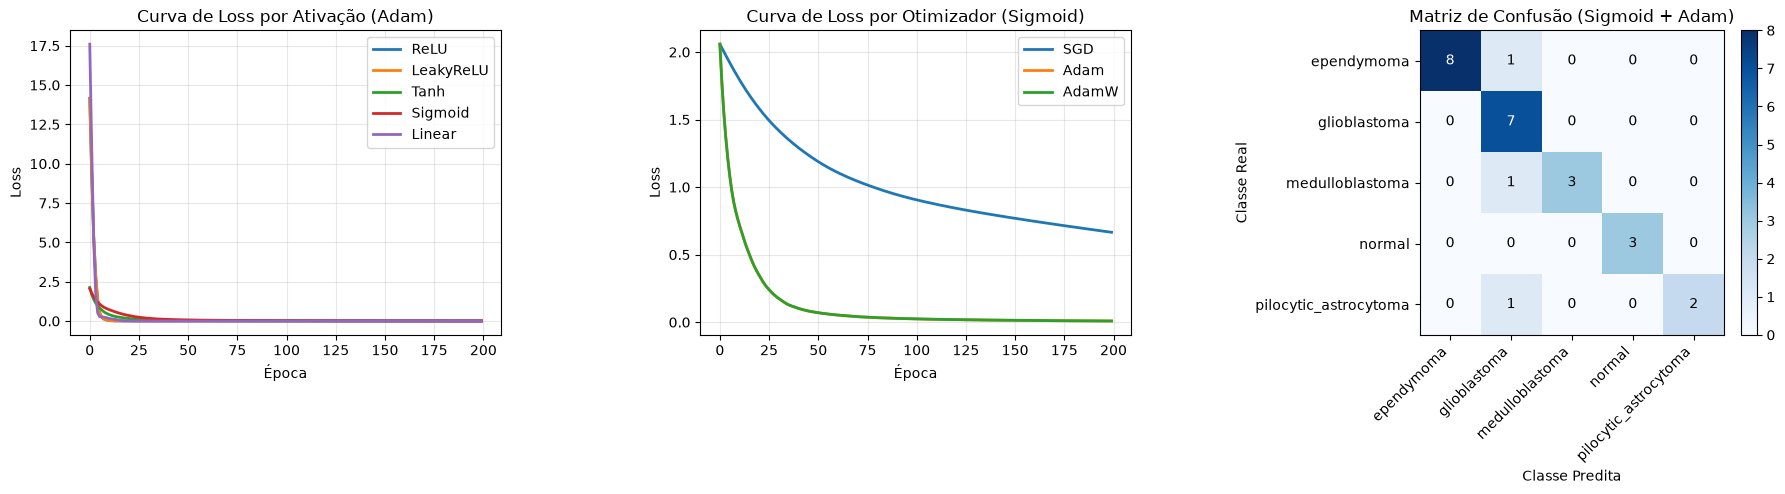

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Comparando Funções de Ativação (com o melhor otimizador)
best_opt_name = best_params["optimizer"].__name__
for act_cls in param_grid["activation"]:
    key = f"{act_cls.__name__} + {best_opt_name}"
    if key in candidate_models:
        axes[0].plot(
            candidate_models[key]["estimator"].loss_history,
            lw=2,
            label=act_cls.__name__,
        )
axes[0].set_title(f"Curva de Loss por Ativação ({best_opt_name})")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Comparando Otimizadores (com a melhor função de ativação)
best_act_name = best_params["activation"].__name__
for opt_cls in param_grid["optimizer"]:
    key = f"{best_act_name} + {opt_cls.__name__}"
    if key in candidate_models:
        axes[1].plot(
            candidate_models[key]["estimator"].loss_history,
            lw=2,
            label=opt_cls.__name__,
        )
axes[1].set_title(f"Curva de Loss por Otimizador ({best_act_name})")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# 3. Matriz de Confusão do melhor modelo no conjunto de teste
im = axes[2].imshow(cm, cmap="Blues")
axes[2].set_xticks(range(len(class_names)), class_names, rotation=45, ha="right")
axes[2].set_yticks(range(len(class_names)), class_names)
axes[2].set_title(f"Matriz de Confusão ({best_act_name} + {best_opt_name})")
axes[2].set_xlabel("Classe Predita")
axes[2].set_ylabel("Classe Real")
for i in range(len(class_names)):
    for j in range(len(class_names)):
        axes[2].text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black",
        )
fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

## 6. Conclusão

- Desempenho da Rede Neural no teste:
    
    O MLPClassifier (com ativação Sigmoid, otimizador Adam,lr=0.01 e camada oculta de tamanho 32) superou expressivamente o Majority Baseline, alcançando alta acurácia e F1-macro no conjunto de teste independente.

- Principais limitações (opcional):
    
    Arquitetura fixa em 1 camada oculta: O MLPClassifier não permite encadear múltiplas camadas intermediárias (ex.: hidden_layers=[128, 64]), limitando a capacidade de extrair representações hierárquicas mais profundas.

    Ausência de mecanismos de regularização na rede: A biblioteca não possui implementação de *Dropout* nem penalidades $L_1/L_2$ (Weight Decay) integradas diretamente à perda do classificador, aumentando a vulnerabilidade a sobreajuste (*overfitting*).

    Falta de Early Stopping:** O loop de treino roda estritamente pelo número de épocas estipulado, sem monitoramento dinâmico da perda de validação para interromper o treinamento no ponto ótimo.